In [6]:
# Import of the necessary python libraries
import pandas as pd
import pandas_datareader as pdr
import pandas_datareader.data as web
import numpy as np
import scipy.stats as scs
import matplotlib.pyplot as plt

In [7]:
# Define the risk-free rate rf for the calculation (for calculation of rf see the Excel tables)
rf = 0.0509

In [8]:
prices = pd.read_csv('BRICS_L_M_S_CORONA.csv', delimiter=';',decimal=',', thousands="." , skip_blank_lines=True , index_col=0, parse_dates=True, infer_datetime_format=True)
prices.head()

/tmp/ipykernel_418/450694028.py:1: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  prices = pd.read_csv('BRICS_L_M_S_CORONA.csv', delimiter=';',decimal=',', thousands="." , skip_blank_lines=True , index_col=0, parse_dates=True, infer_datetime_format=True)


,Large Cap,Mid Cap,Small Cap
Date,,,
01.10.2019,12022.18,2392.28,1778.33
02.10.2019,11954.65,2367.52,1767.25
03.10.2019,12014.23,2375.83,1772.28
04.10.2019,11999.71,2387.97,1771.04
07.10.2019,11955.71,2367.04,1758.53


In [9]:
# Calculating the Covariance-Matrix of the chosen indices
cov_matrix = prices.pct_change().apply(lambda x: np.log(1+x)).cov()
cov_matrix

,Large Cap,Mid Cap,Small Cap
Large Cap,0.000224,0.000240,0.000233
Mid Cap,0.000240,0.000299,0.000288
Small Cap,0.000233,0.000288,0.000306


In [10]:
# Ensure the index contains dates
prices.index = pd.to_datetime(prices.index, dayfirst=True)

# Calculate the expected annualized returns
e_r = prices.resample("D").last().pct_change().mean() * 181
e_r


/tmp/ipykernel_418/3219971785.py:5: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  e_r = prices.resample("D").last().pct_change().mean() * 181


,0
Large Cap,0.075974
Mid Cap,0.071332
Small Cap,-0.006025


In [11]:
# Calculating the standard diviation / volatility of the chosen indices
sd = prices.pct_change().apply(lambda x: np.log(1+x)).std().apply(lambda x: x*np.sqrt(181))
sd

,0
Large Cap,0.201209
Mid Cap,0.232734
Small Cap,0.235474


In [12]:
# Concatenation of the indices and the returns/volatility
assets = pd.concat([e_r, sd], axis=1)
assets.columns = ["Returns", "Volatility"]
assets

,Returns,Volatility
Large Cap,0.075974,0.201209
Mid Cap,0.071332,0.232734
Small Cap,-0.006025,0.235474


In [13]:
# Creating blanco lists for the portfolio return, portfolio volatility and the weights of the particular indices
# In addition, setting the number of determined portfolios to 2500 --> Law of large numbers
p_ret = []
p_vol = []
p_weights = []

num_assets = len(prices.columns)
num_portfolios = 2500

In [14]:
# Calculation of the weights of the particular indices by frequently random
for portfolio in range(num_portfolios):
    weights = np.random.random(num_assets)
    weights = weights/np.sum(weights)
    p_weights.append(weights)
    returns = np.dot(weights, e_r)
    p_ret.append(returns)
    var = cov_matrix.mul(weights, axis=0).mul(weights, axis=1).sum().sum()
    sd = np.sqrt(var)
    ann_sd = sd*np.sqrt(250)
    p_vol.append(ann_sd)

In [15]:
# Return and Volatility Variables for plotting the portfolios
port_ret = np.array(p_ret)
port_vol = np.array(p_vol)

In [16]:
data = {"Returns": p_ret, "Volatility": p_vol}

In [17]:
for counter, symbol in enumerate(prices.columns.tolist()):
    data[symbol+" weight"] = [w[counter] for w in p_weights]

In [18]:
portfolios = pd.DataFrame(data)

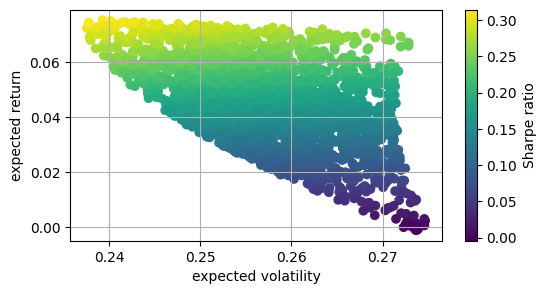

In [19]:
# Plotting the 2500 calculated portfolios and the Sharpe ratio in the colorbar
plt.figure(figsize=(6, 3))
plt.scatter(port_vol,port_ret,c=port_ret/port_vol, marker='o')
plt.grid(True)
plt.xlabel('expected volatility')
plt.ylabel('expected return')
plt.colorbar(label='Sharpe ratio')

In [20]:
# Summary of the MVP with Return, Volatility and the particular weights
min_var_port = portfolios.iloc[portfolios["Volatility"].idxmin()]
min_var_port

,231
Returns,0.072391
Volatility,0.237553
Large Cap weight,0.927008
Mid Cap weight,0.031050
Small Cap weight,0.041942


In [21]:
sharpe_ratio_mvp = (min_var_port["Returns"] - rf) / min_var_port["Volatility"]
sharpe_ratio_mvp

np.float64(0.0904682894295689)

/tmp/ipykernel_418/2469474991.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.scatter(min_var_port[1], min_var_port[0], color="r")


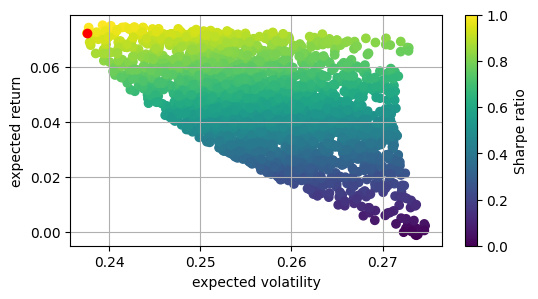

In [22]:
# Visualization of the MVP into the portfolio figure with a red point
plt.subplots(figsize=(6,3))
plt.scatter(portfolios["Volatility"], portfolios["Returns"], c = portfolios["Returns"]/portfolios["Volatility"])
plt.scatter(min_var_port[1], min_var_port[0], color="r")
plt.grid(True)
plt.xlabel('expected volatility')
plt.ylabel('expected return')
plt.colorbar(label='Sharpe ratio')

In [23]:
# The portfolio with the maximum sharpe ratio is saved in the variable optimal_risky_portfolio and the summary is shown below
optimal_risky_portfolio = portfolios.iloc[((portfolios["Returns"]-rf)/portfolios["Volatility"]).idxmax()]
optimal_risky_portfolio

,1395
Returns,0.075239
Volatility,0.239270
Large Cap weight,0.859250
Mid Cap weight,0.139685
Small Cap weight,0.001065


In [24]:
sharpe_ratio = (optimal_risky_portfolio["Returns"] - rf) / optimal_risky_portfolio["Volatility"]
sharpe_ratio

np.float64(0.10171998068945938)

/tmp/ipykernel_418/1299486737.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.scatter(min_var_port[1], min_var_port[0], color="r")
/tmp/ipykernel_418/1299486737.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.scatter(optimal_risky_portfolio[1], optimal_risky_portfolio[0], color="b")


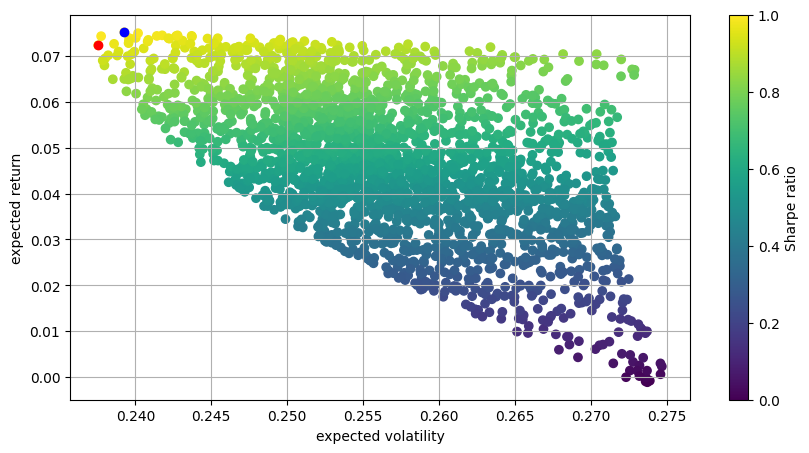

In [26]:
# Visualization of the optimal risky portfolio into the previous figure with a blue point
plt.subplots(figsize=(10,5))
plt.scatter(portfolios["Volatility"], portfolios["Returns"], c = portfolios["Returns"]/portfolios["Volatility"])
plt.scatter(min_var_port[1], min_var_port[0], color="r")
plt.scatter(optimal_risky_portfolio[1], optimal_risky_portfolio[0], color="b")
plt.grid(True)
plt.xlabel('expected volatility')
plt.ylabel('expected return')
plt.colorbar(label='Sharpe ratio')
# Safe the figure to the computer (optional)
plt.savefig("port_emerg_covid.png", dpi=300, bbox_inches="tight")